<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/gg_lockup.png" alt="Global Gateway · European Union" height="64"/>

**Financiado pela União Europeia** · Programa de Parceria Espacial África–UE · Reforço dos Alertas Precoces em África (SEWA)

# Poeiras do deserto sobre a África Ocidental com o CAMS 🏜️
### Serviço de Monitorização da Atmosfera do Copernicus · conta gratuita

> ⚠️ **Tradução:** este notebook foi traduzido do inglês com a ajuda de IA e revisto na medida do possível. Em caso de dúvida, prevalece a [versão inglesa](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/dust_cams.ipynb). Comunique quaisquer erros no [GitHub](https://github.com/piddy376/visits-weather-notebooks/issues).

🌐 [English](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/dust_cams.ipynb) · [Français](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/dust_cams_fr.ipynb) · [Português](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/dust_cams_pt.ipynb)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/dust_cams_pt.ipynb)

Na estação seca, aproximadamente de novembro a março, o **Harmattan**, vento de nordeste, transporta poeiras do Sara
através do Sahel em direção ao Atlântico. Este notebook cartografa a previsão de poeiras da **previsão global do CAMS**,
produzida pelo ECMWF para a União Europeia, a partir da execução de ontem e até cinco dias.

**O que precisa:** uma conta Google (para usar o Colab) e uma conta Copernicus gratuita (passo abaixo). Tudo corre nos computadores da Google: os dados são descarregados lá, não no seu telemóvel
ou computador, por isso uma ligação lenta ou móvel é suficiente.

| Dados | O que este notebook usa | Licença |
|---|---|---|
| Previsão global do CAMS da composição atmosférica, cerca de 40 km | Espessura ótica dos aerossóis de poeira a 550 nm | licença Copernicus, gratuito |

**Ferramentas:** [earthkit](https://earthkit.ecmwf.int), as ferramentas Python gratuitas e de código aberto do ECMWF para dados meteorológicos e climáticos.

*Clique em **Ambiente de execução → Executar tudo** (Runtime → Run all). O data store coloca os pedidos em fila: o passo 2 pode demorar alguns minutos.*

<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/cams_logoline_pos.png" alt="Copernicus, implemented by ECMWF" height="30"/>

In [ ]:
# Instalar as ferramentas de código aberto (Colab / máquina nova). Alguns minutos da primeira vez.
%pip install -q "earthkit-data[cds]" earthkit-plots

## A sua chave Copernicus gratuita

Os dados Copernicus são gratuitos e abertos, mas os data stores pedem um registo único para gerir a fila de pedidos:
1. Crie uma conta em [cds.climate.copernicus.eu](https://cds.climate.copernicus.eu) (a mesma conta serve para o
   Atmosphere Data Store).
2. Abra a [página do conjunto de dados](https://ads.atmosphere.copernicus.eu/datasets/cams-global-atmospheric-composition-forecasts?tab=download) no Atmosphere Data Store e aceite a licença (no fundo do separador Download). Só precisa de o fazer uma vez.
3. Copie a sua chave API da sua [página de perfil](https://cds.climate.copernicus.eu/profile) e cole-a abaixo.

**Use a sua própria chave.** Cada pessoa que executa este notebook precisa da sua própria conta e chave Copernicus
gratuitas. A célula seguinte pede a chave numa caixa oculta e guarda-a na máquina que executa o notebook (no Colab, uma
máquina temporária apagada quando fecha o separador). A chave nunca fica guardada no notebook: não a cole numa célula de
código e não partilhe um notebook ou captura de ecrã que a mostre. No seu computador, se `~/.cdsapirc` / `~/.adsapirc`
já existirem, a célula não pede nada.

In [2]:
import os
from getpass import getpass
rc = {"~/.cdsapirc": "https://cds.climate.copernicus.eu/api", "~/.adsapirc": "https://ads.atmosphere.copernicus.eu/api"}
missing = [p for p in rc if not os.path.exists(os.path.expanduser(p))]
if missing:
    key = getpass("Chave API Copernicus: ")
    for p in missing:
        with open(os.path.expanduser(p), "w") as f:
            f.write(f"url: {rc[p]}\nkey: {key}\n")
print("Chave Copernicus pronta")

Chave Copernicus pronta


In [3]:
import pyproj                     # importar antes de earthkit.data (evita um erro ao fechar)
import datetime as dt
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np

DIAS = ["segunda-feira", "terça-feira", "quarta-feira", "quinta-feira", "sexta-feira", "sábado", "domingo"]
MESES = ["janeiro", "fevereiro", "março", "abril", "maio", "junho", "julho", "agosto", "setembro", "outubro",
         "novembro", "dezembro"]
def dia(d): return f"{DIAS[d.weekday()]}, {d.day} de {MESES[d.month - 1]}"     # datas em português
def data_pt(d): return f"{d.day} de {MESES[d.month - 1]} de {d.year}"

## 1 · Escolher a execução, o prazo e a área

In [4]:
AREA = [27.0, -26.0, 4.0, 10.0]                                   # norte, oeste, sul, este
DATE = (dt.date.today() - dt.timedelta(days=1)).isoformat()      # a execução de ontem está sempre completa
LEAD = 72                                                         # horas após as 00 UTC, até 120
CITIES = [("Dakar", 14.716, -17.467), ("Saint-Louis", 16.018, -16.489), ("Touba", 14.850, -15.883),
          ("Tambacounda", 13.771, -13.667), ("Ziguinchor", 12.583, -16.272), ("Kédougou", 12.557, -12.174)]

def label_cities(ax):
    for name, la, lo in CITIES:
        ax.scatter([lo], [la], s=36, color="#ffd23f", edgecolors="#1a1a1a", linewidths=0.8, zorder=10,
                   transform=ccrs.PlateCarree())
        ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

## 2 · Descarregar a previsão de poeiras

In [5]:
cams = ekd.from_source("ads", "cams-global-atmospheric-composition-forecasts", {
    "variable": "dust_aerosol_optical_depth_550nm", "date": f"{DATE}/{DATE}", "time": "00:00",
    "type": "forecast", "leadtime_hour": str(LEAD), "area": AREA, "data_format": "grib"}).to_xarray()
duaod = cams[list(cams.data_vars)[0]].squeeze()
valid = dt.datetime.fromisoformat(DATE) + dt.timedelta(hours=LEAD)
print(f"Espessura ótica das poeiras até {float(duaod.max()):.2f} em {dia(valid)} às {valid:%H}:00 UTC")

Espessura ótica das poeiras até 0.44 em domingo, 22 de novembro às 00:00 UTC


## 3 · Cartografá-la

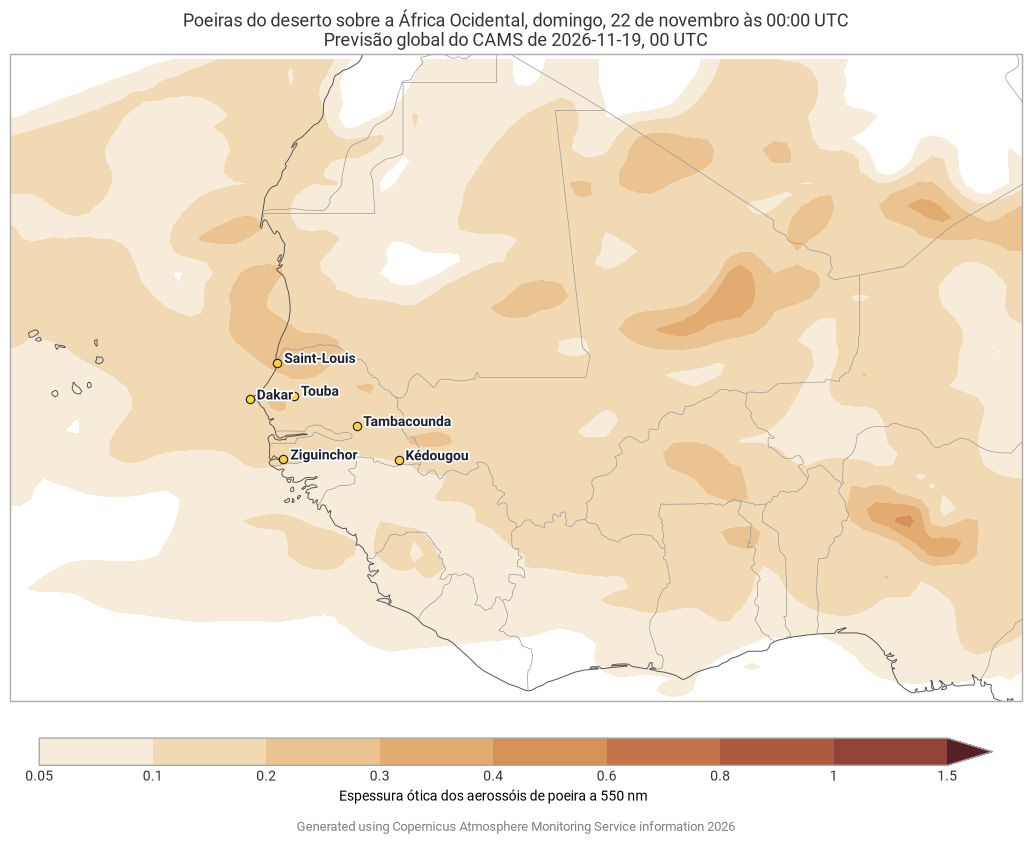

In [6]:
colors = ["#f6ecd9", "#efd3a8", "#e6b77d", "#d9955a", "#c27046", "#a34f3c", "#7d3533", "#562126"]
style = ekp.styles.Style(levels=[0.05, 0.1, 0.2, 0.3, 0.4, 0.6, 0.8, 1.0, 1.5], colors=colors, extend="max")
chart = ekp.Map(domain=[AREA[1], AREA[3], AREA[2], AREA[0]], figsize=(12, 8))
chart.contourf(duaod, style=style)
chart.coastlines(linewidth=0.7); chart.borders(linewidth=0.5)
label_cities(chart.ax)
chart.legend(label="Espessura ótica dos aerossóis de poeira a 550 nm")
chart.title(f"Poeiras do deserto sobre a África Ocidental, {dia(valid)} às {valid:%H}:00 UTC\nPrevisão global do CAMS de {DATE}, 00 UTC", fontsize=13)
chart.attribution("Generated using Copernicus Atmosphere Monitoring Service information 2026")
chart.save("dust_cams_pt.png")
chart.show()

## 4 · A sua vez 🌍

- **Percorrer a semana:** mude `LEAD` de 0 a 120 em passos de 3.
- **Poeiras junto ao solo:** a variável `"dust_aerosol_0.9-20um_mixing_ratio"` dá as poeiras grossas; ou experimente
  `"particulate_matter_10um"` (multiplique por 1e9 para µg/m³), que no Sahel, na estação seca, é sobretudo poeira.
- O CAMS global tem cerca de 40 km de resolução: mostra para onde vão as poeiras, não o detalhe cidade a cidade.

### Dados e licença
Os dados Copernicus são gratuitos e abertos sob a licença Copernicus (CC-BY 4.0). Crédito:
*Generated using Copernicus Atmosphere Monitoring Service information 2026.* O ECMWF opera o Serviço de Monitorização da Atmosfera do Copernicus (CAMS) e o
Serviço Copernicus para as Alterações Climáticas (C3S) em nome da União Europeia.

[Climate Data Store](https://cds.climate.copernicus.eu) · [Atmosphere Data Store](https://ads.atmosphere.copernicus.eu) ·
[earthkit](https://earthkit.ecmwf.int)